In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv('student-mat.csv')
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
print(df.shape)
print(df.columns.tolist())
df.info()
display(df.describe().T)

print('Missing values:', df.isna().sum().sum())
print('Duplicates:', df.duplicated().sum())
print('Students with G3 = 0:', (df['G3'] == 0).sum())

cat_cols = ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob',
            'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities',
            'nursery', 'higher', 'internet', 'romantic']
for c in cat_cols:
    print(df[c].value_counts().to_dict())

(395, 33)
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    obje

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


Missing values: 0
Duplicates: 0
Students with G3 = 0: 38
{'GP': 349, 'MS': 46}
{'F': 208, 'M': 187}
{'U': 307, 'R': 88}
{'GT3': 281, 'LE3': 114}
{'T': 354, 'A': 41}
{'other': 141, 'services': 103, 'at_home': 59, 'teacher': 58, 'health': 34}
{'other': 217, 'services': 111, 'teacher': 29, 'at_home': 20, 'health': 18}
{'course': 145, 'home': 109, 'reputation': 105, 'other': 36}
{'mother': 273, 'father': 90, 'other': 32}
{'no': 344, 'yes': 51}
{'yes': 242, 'no': 153}
{'no': 214, 'yes': 181}
{'yes': 201, 'no': 194}
{'yes': 314, 'no': 81}
{'yes': 375, 'no': 20}
{'yes': 329, 'no': 66}
{'no': 263, 'yes': 132}


In [4]:
df = df.drop_duplicates().reset_index(drop=True)
for c in cat_cols:
    df[c] = df[c].astype('category')
df_nz = df[df['G3'] > 0].copy()
print(df.shape, df_nz.shape)

(395, 33) (357, 33)


In [5]:

df['passed'] = (df['G3'] >= 10).astype(int)


df['sex_num'] = (df['sex'] == 'M').astype(int)


df['alcohol'] = (df['Dalc'] + df['Walc']) / 2


df['parents_edu'] = (df['Medu'] + df['Fedu']) / 2


df_nz = df[df['G3'] > 0].copy()

print(df.shape, df_nz.shape)
df[['G3', 'passed', 'sex_num', 'alcohol', 'parents_edu']].head()

(395, 37) (357, 37)


,G3,passed,sex_num,alcohol,parents_edu
0,6,0,0,1.0,4.0
1,6,0,0,1.0,1.0
2,10,1,0,2.5,1.0
3,15,1,0,1.0,3.0
4,10,1,0,1.5,3.0


In [6]:
df.info()
print()
print('Missing values:', df.isna().sum().sum())
print('Share of students who passed:')
print(df['passed'].value_counts(normalize=True).round(3))
print()
df[['G1', 'G2', 'G3', 'passed', 'sex_num', 'alcohol', 'parents_edu']].describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 37 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   school       395 non-null    category
 1   sex          395 non-null    category
 2   age          395 non-null    int64   
 3   address      395 non-null    category
 4   famsize      395 non-null    category
 5   Pstatus      395 non-null    category
 6   Medu         395 non-null    int64   
 7   Fedu         395 non-null    int64   
 8   Mjob         395 non-null    category
 9   Fjob         395 non-null    category
 10  reason       395 non-null    category
 11  guardian     395 non-null    category
 12  traveltime   395 non-null    int64   
 13  studytime    395 non-null    int64   
 14  failures     395 non-null    int64   
 15  schoolsup    395 non-null    category
 16  famsup       395 non-null    category
 17  paid         395 non-null    category
 18  activities   395 non-null    c

,G1,G2,G3,passed,sex_num,alcohol,parents_edu
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,10.91,10.71,10.42,0.67,0.47,1.89,2.64
std,3.32,3.76,4.58,0.47,0.50,0.99,0.98
min,3.00,0.00,0.00,0.00,0.00,1.00,0.50
25%,8.00,9.00,8.00,0.00,0.00,1.00,2.00
50%,11.00,11.00,11.00,1.00,0.00,1.50,2.50
75%,13.00,13.00,14.00,1.00,1.00,2.50,3.50
max,19.00,19.00,20.00,1.00,1.00,5.00,4.00


# Student Performance Analysis

## 1. Dataset Overview

The dataset (`student-mat.csv`) contains records of **395 secondary-school
students** from two Portuguese schools. It describes their performance in the
**Mathematics** course together with demographic, social and school-related
attributes (33 columns in total). The data comes from the UCI "Student
Performance" dataset (Cortez & Silva, 2008).

| Group | Variables |
|---|---|
| Demographic | `school`, `sex`, `age`, `address`, `famsize` |
| Family | `Medu`, `Fedu` (parents' education), `Mjob`, `Fjob`, `guardian`, `famrel` |
| Study habits | `studytime`, `failures`, `schoolsup`, `famsup`, `paid`, `higher` |
| Lifestyle | `freetime`, `goout`, `Dalc`, `Walc` (alcohol use), `health`, `romantic`, `internet` |
| Attendance | `absences` |
| Grades | `G1`, `G2`, `G3` (first period, second period, final), 0-20 scale |

**Target variable:** `G3`, the final grade.

**Data quality:** no missing values and no duplicate rows. 38 students have a final grade of 0. The reason for these zero grades cannot be determined from the available data, so the analysis is also repeated without them.

**Prepared variables:** `passed` (1 if `G3` >= 10), `sex_num`, `alcohol`
(mean of `Dalc` and `Walc`) and `parents_edu` (mean of `Medu` and `Fedu`).

**Limitations:** the data is observational and covers one subject and two
schools, so the results show associations, not causes.

## 2. Research Questions

1. **Sample composition:** What does the sample look like in terms of sex,
   school and age?
2. **Grades:** How are the final grades distributed, and do they differ by
   sex or school?
3. **Relationships:** Which factors (study time, past failures, absences,
   parents' education, alcohol use) are related to the final grade?
4. **Prediction:** How well can a linear regression model predict `G3`, with
   and without the previous grades `G1` and `G2`?
5. **Classification:** Can a logistic regression model predict whether a
   student passes (`G3` >= 10)?

sex
F    52.7
M    47.3
Name: proportion, dtype: float64 

school
GP    88.4
MS    11.6
Name: proportion, dtype: float64 

address
U    77.7
R    22.3
Name: proportion, dtype: float64 

age
15     82
16    104
17     98
18     82
19     24
20      3
21      1
22      1
Name: count, dtype: int64 



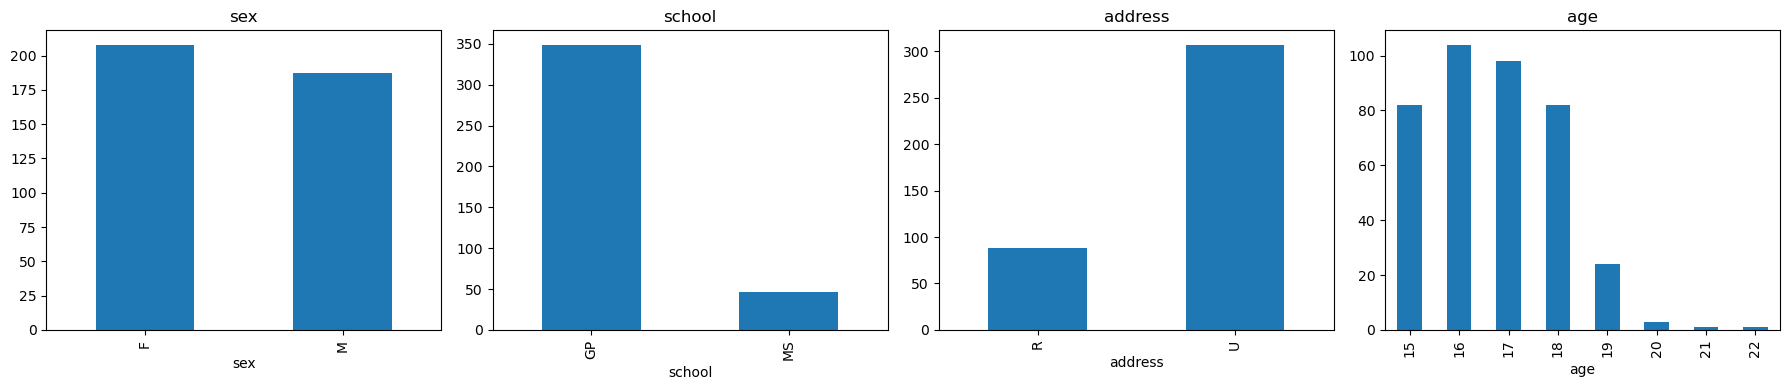

In [7]:

for c in ['sex', 'school', 'address']:
    print((df[c].value_counts(normalize=True) * 100).round(1), '\n')

print(df['age'].value_counts().sort_index(), '\n')


fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ['sex', 'school', 'address', 'age']):
    df[c].value_counts().sort_index().plot(kind='bar', ax=ax, title=c)
plt.tight_layout()
plt.show()

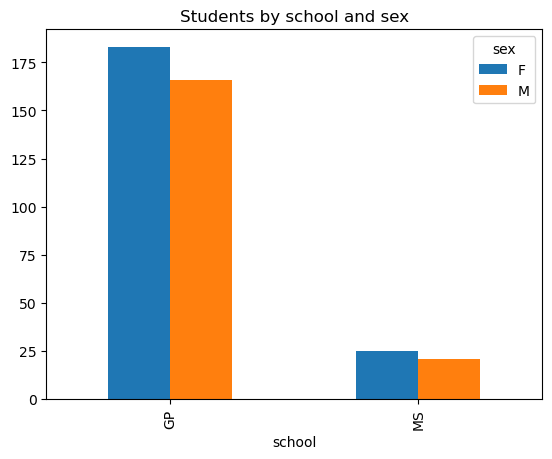

In [8]:
pd.crosstab(df['school'], df['sex']).plot(kind='bar', title='Students by school and sex')
plt.show()

The sample consists of slightly more female students (approximately 53%) than male students. Nearly 90% of the participants attend GP school, while around 78% reside in urban areas. The majority of students are aged between 15 and 18 years.

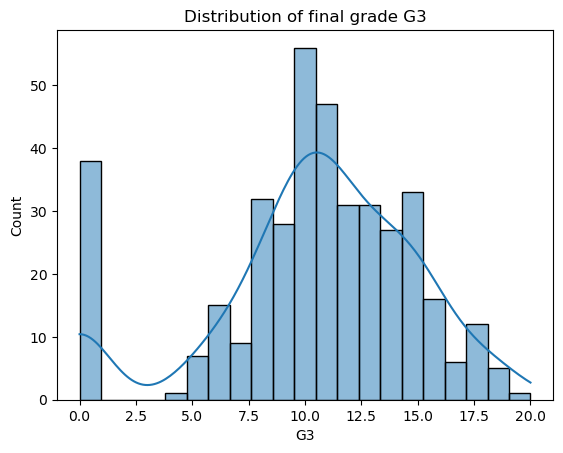

Skewness: -0.73


count    395.00
mean      10.42
std        4.58
min        0.00
25%        8.00
50%       11.00
75%       14.00
max       20.00
Name: G3, dtype: float64

In [9]:
sns.histplot(data=df, x='G3', bins=21, kde=True)
plt.title('Distribution of final grade G3')
plt.show()

print('Skewness:', round(df['G3'].skew(), 2))
df['G3'].describe().round(2)

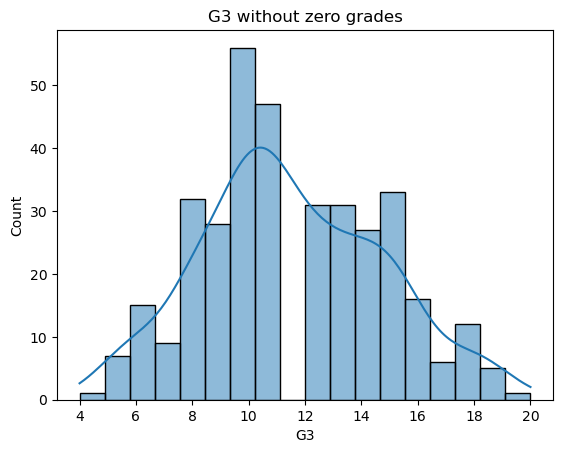

In [10]:
sns.histplot(data=df_nz, x='G3', bins=18, kde=True)
plt.title('G3 without zero grades')
plt.show()

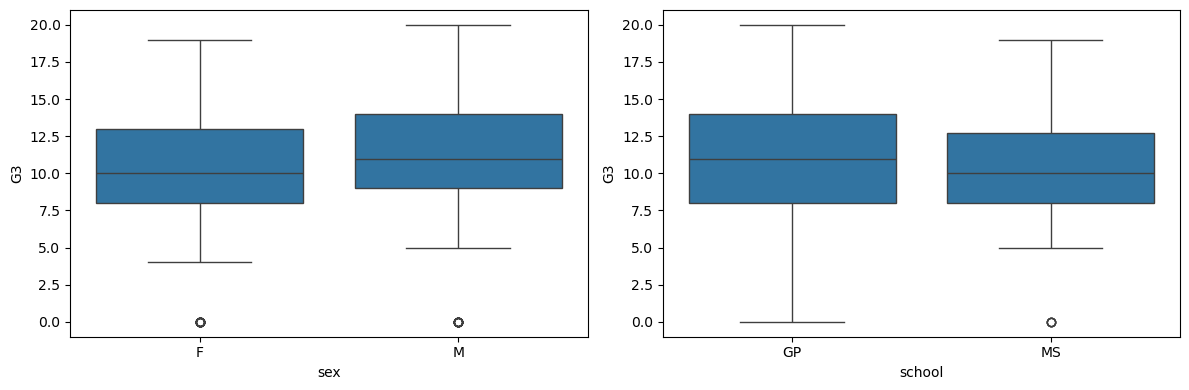

     count   mean  median
sex                      
F      208   9.97    10.0
M      187  10.91    11.0
        count   mean  median
school                      
GP        349  10.49    11.0
MS         46   9.85    10.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='sex', y='G3', ax=axes[0])
sns.boxplot(data=df, x='school', y='G3', ax=axes[1])
plt.tight_layout()
plt.show()

print(df.groupby('sex', observed=True)['G3'].agg(['count', 'mean', 'median']).round(2))
print(df.groupby('school', observed=True)['G3'].agg(['count', 'mean', 'median']).round(2))

In [12]:
m = df[df['sex'] == 'M']['G3']
f = df[df['sex'] == 'F']['G3']
print('M vs F:', stats.ttest_ind(m, f, equal_var=False))

gp = df[df['school'] == 'GP']['G3']
ms = df[df['school'] == 'MS']['G3']
print('GP vs MS:', stats.ttest_ind(gp, ms, equal_var=False))

M vs F: TtestResult(statistic=2.0650572003629564, pvalue=0.03957700303089975, df=390.5693560400321)
GP vs MS: TtestResult(statistic=0.9555475253722291, pvalue=0.3431316933314036, df=60.05392977938651)


The distribution of final grades is negatively skewed, with most students scoring between 10 and 12, while 38 students received a grade of 0. Male students achieved a slightly higher average grade than female students (approximately 10.9 compared to 10.0), and this difference was statistically significant (p = 0.04). No statistically significant difference was found between the two schools (p = 0.34), although it is worth noting that the MS school has a relatively small sample size of 46 students. Overall, approximately 67% of students successfully passed the course (G3 ≥ 10).

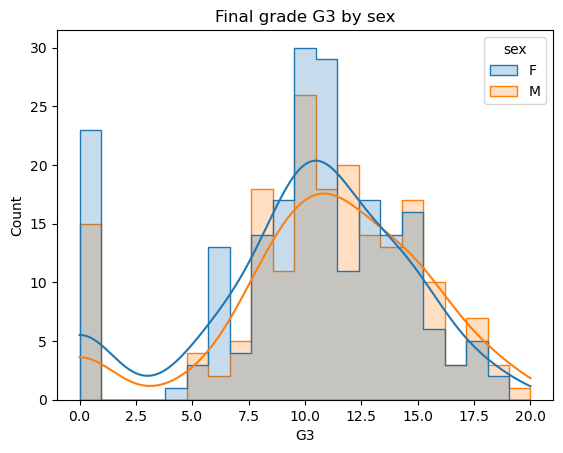

In [13]:
sns.histplot(data=df, x='G3', hue='sex', bins=21, kde=True, element='step')
plt.title('Final grade G3 by sex')
plt.show()

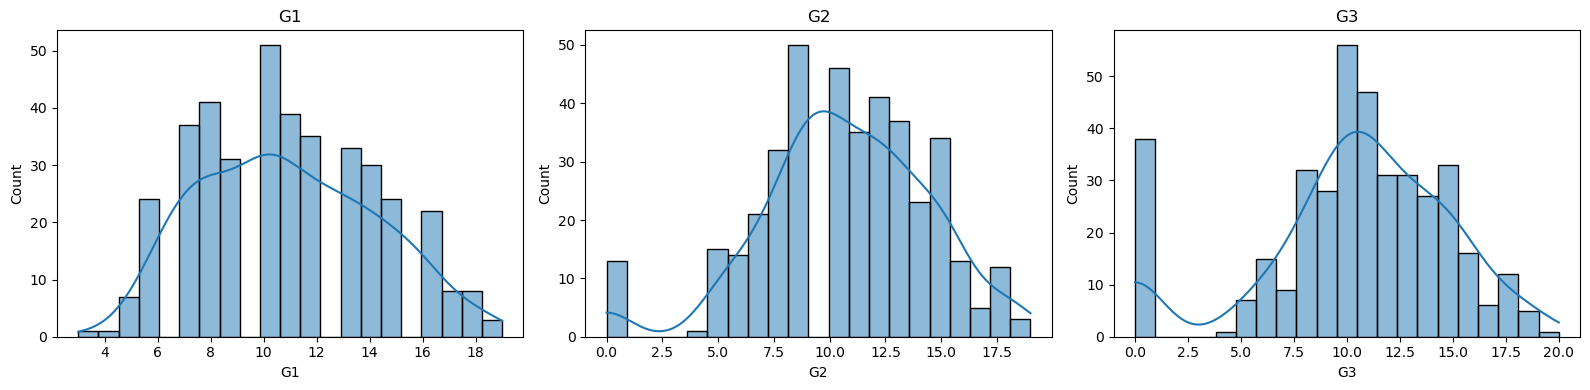

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ['G1', 'G2', 'G3']):
    sns.histplot(data=df, x=c, bins=21, kde=True, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

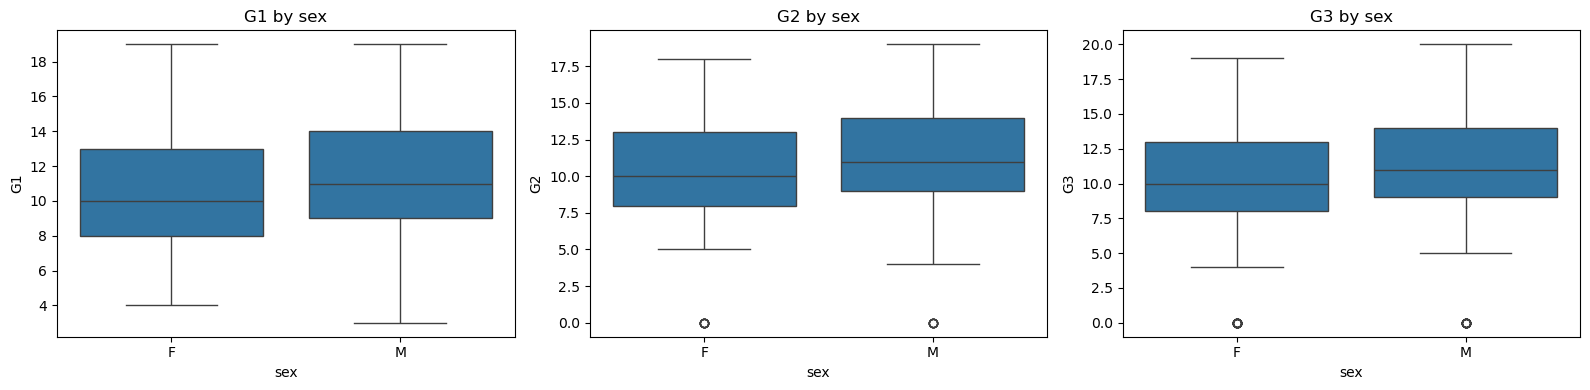

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ['G1', 'G2', 'G3']):
    sns.boxplot(data=df, x='sex', y=c, ax=ax)
    ax.set_title(c + ' by sex')
plt.tight_layout()
plt.show()

The histograms of G1, G2 and G3 have a similar shape, but only G3 has a separate peak at zero. Boys and girls have a similar distribution of grades, with a slightly higher median for boys. The boxplots show the same small difference in all three grades.

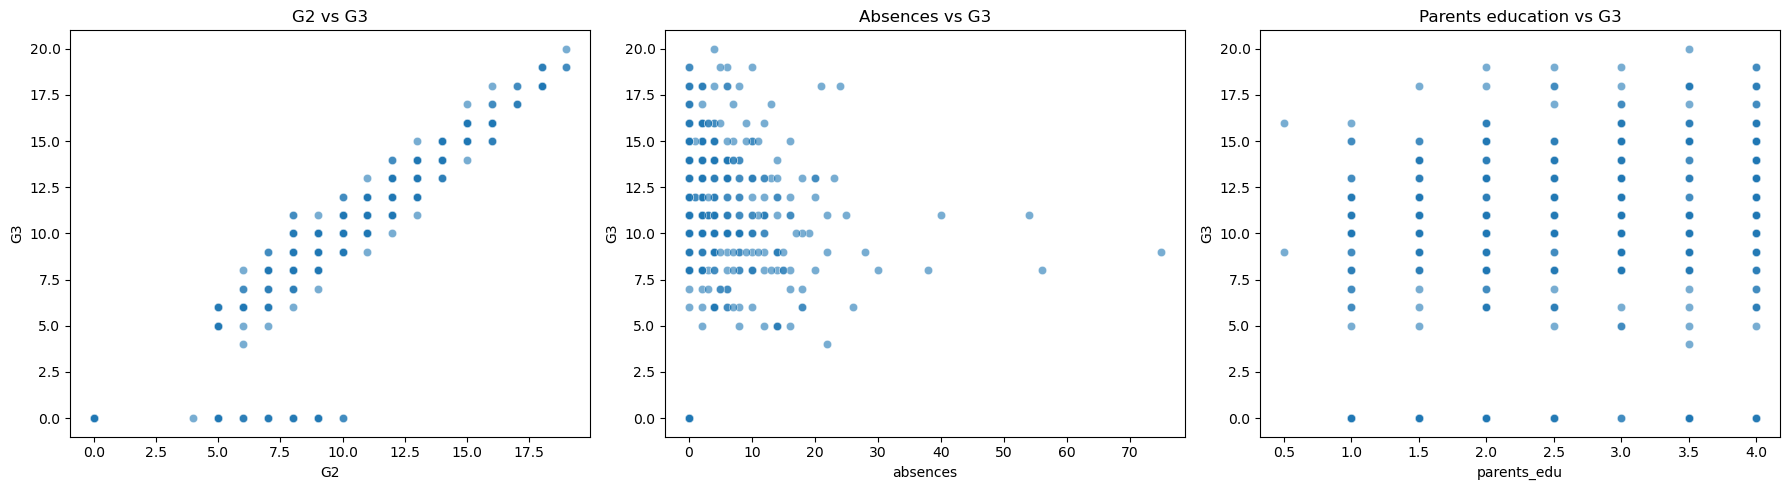

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x='G2', y='G3', ax=axes[0], alpha=0.6)
axes[0].set_title('G2 vs G3')
sns.scatterplot(data=df, x='absences', y='G3', ax=axes[1], alpha=0.6)
axes[1].set_title('Absences vs G3')
sns.scatterplot(data=df, x='parents_edu', y='G3', ax=axes[2], alpha=0.6)
axes[2].set_title('Parents education vs G3')
plt.tight_layout()
plt.show()

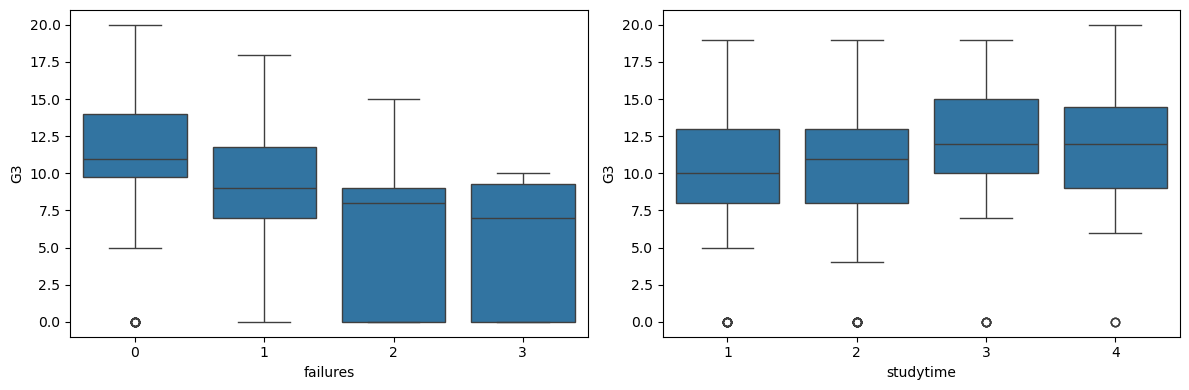

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='failures', y='G3', ax=axes[0])
sns.boxplot(data=df, x='studytime', y='G3', ax=axes[1])
plt.tight_layout()
plt.show()

studytime      0.10
failures      -0.36
absences       0.03
parents_edu    0.21
alcohol       -0.06
age           -0.16
G1             0.80
G2             0.90
G3             1.00
Name: G3, dtype: float64


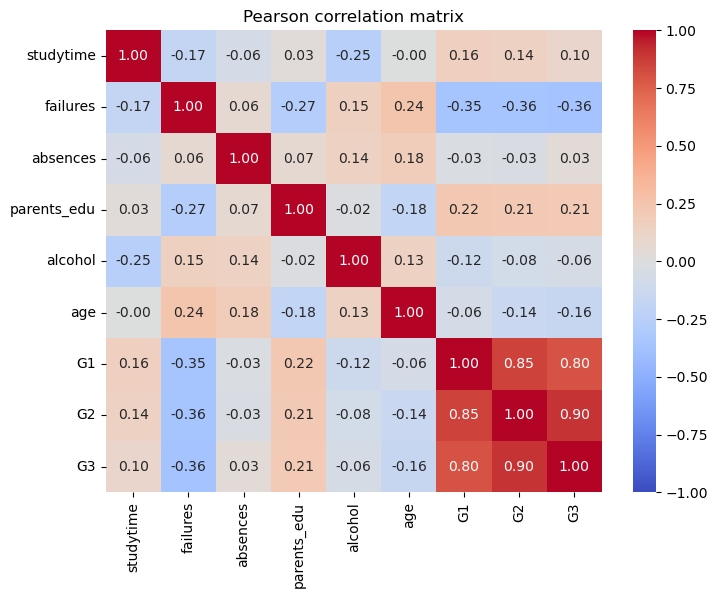

In [18]:
num_cols = ['studytime', 'failures', 'absences', 'parents_edu', 'alcohol', 'age', 'G1', 'G2', 'G3']
corr = df[num_cols].corr()
print(corr['G3'].round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Pearson correlation matrix')
plt.show()

In [19]:
for c in ['studytime', 'failures', 'absences', 'parents_edu', 'alcohol']:
    r, p = stats.pearsonr(df[c], df['G3'])
    print(f'{c:12s} r = {r:.2f}   p = {p:.3g}')

studytime    r = 0.10   p = 0.0521
failures     r = -0.36   p = 1.47e-13
absences     r = 0.03   p = 0.497
parents_edu  r = 0.21   p = 3.96e-05
alcohol      r = -0.06   p = 0.248


In [20]:
print(df_nz[num_cols].corr()['G3'].round(2))

studytime      0.13
failures      -0.29
absences      -0.21
parents_edu    0.19
alcohol       -0.19
age           -0.14
G1             0.89
G2             0.97
G3             1.00
Name: G3, dtype: float64


Final grade (G3) shows a very strong positive correlation with previous grades, particularly G2 (r = 0.90) and G1 (r = 0.80). Among the other variables, the number of past failures has the strongest negative association with G3 (r = -0.36), while parents' education has a weak positive correlation (r = 0.21). Absences and alcohol consumption show almost no correlation with final grades when considering the full dataset. However, after excluding students with a final grade of 0, both relationships become negative (approximately r = -0.21 and r = -0.19, respectively). This suggests that the zero grades may mask some of the underlying associations.

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error


In [22]:

df['higher_num'] = (df['higher'] == 'yes').astype(int)
df['internet_num'] = (df['internet'] == 'yes').astype(int)
df['romantic_num'] = (df['romantic'] == 'yes').astype(int)


df_nz = df[df['G3'] > 0].copy()


base = ['studytime', 'failures', 'absences', 'parents_edu', 'alcohol', 'age',
        'sex_num', 'higher_num', 'internet_num', 'romantic_num',
        'goout', 'health', 'freetime', 'famrel']

In [23]:
for c in ['G2', 'G1', 'failures', 'parents_edu', 'age', 'studytime', 'alcohol', 'absences']:
    X = df[[c]]
    y = df['G3']
    model = LinearRegression().fit(X, y)
    r2 = r2_score(y, model.predict(X))
    print(f'{c:12s} R2 = {r2:.3f}   slope = {model.coef_[0]:.2f}')

G2           R2 = 0.819   slope = 1.10
G1           R2 = 0.642   slope = 1.11
failures     R2 = 0.130   slope = -2.22
parents_edu  R2 = 0.042   slope = 0.96
age          R2 = 0.026   slope = -0.58
studytime    R2 = 0.010   slope = 0.53
alcohol      R2 = 0.003   slope = -0.27
absences     R2 = 0.001   slope = 0.02


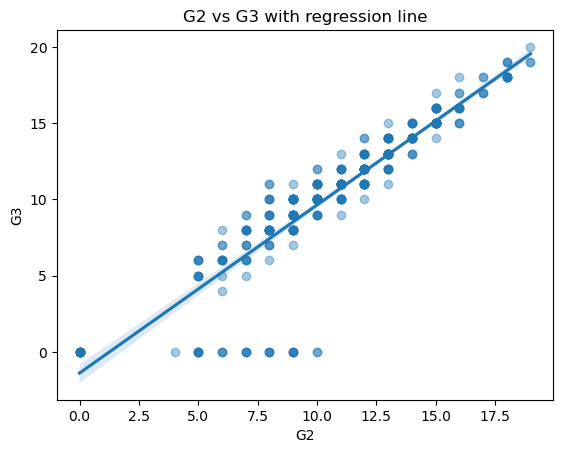

In [24]:
sns.regplot(data=df, x='G2', y='G3', scatter_kws={'alpha': 0.4})
plt.title('G2 vs G3 with regression line')
plt.show()

In [25]:
def run_model(cols, data, name):
    X = data[cols]
    y = data['G3']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression().fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f'{name:28s} train R2 = {model.score(X_train, y_train):.3f}   '
          f'test R2 = {r2_score(y_test, pred):.3f}   test MAE = {mean_absolute_error(y_test, pred):.2f}')
    return model, X, y_test, pred

m_with, _, _, _ = run_model(base + ['G1', 'G2'], df, 'All data, with G1 and G2')
m_without, X_wo, y_wo, pred_wo = run_model(base, df, 'All data, without G1/G2')
run_model(base + ['G1', 'G2'], df_nz, 'No zeros, with G1 and G2')
_ = run_model(base, df_nz, 'No zeros, without G1/G2')

All data, with G1 and G2     train R2 = 0.850   test R2 = 0.771   test MAE = 1.40
All data, without G1/G2      train R2 = 0.215   test R2 = 0.125   test MAE = 3.36
No zeros, with G1 and G2     train R2 = 0.940   test R2 = 0.931   test MAE = 0.62
No zeros, without G1/G2      train R2 = 0.195   test R2 = 0.179   test MAE = 2.35


In [26]:
print(pd.Series(m_without.coef_, index=X_wo.columns).round(2).sort_values())

failures       -1.77
romantic_num   -0.87
goout          -0.40
health         -0.19
age            -0.14
alcohol        -0.01
absences        0.06
freetime        0.20
famrel          0.20
parents_edu     0.33
studytime       0.69
internet_num    0.75
sex_num         1.35
higher_num      1.79
dtype: float64


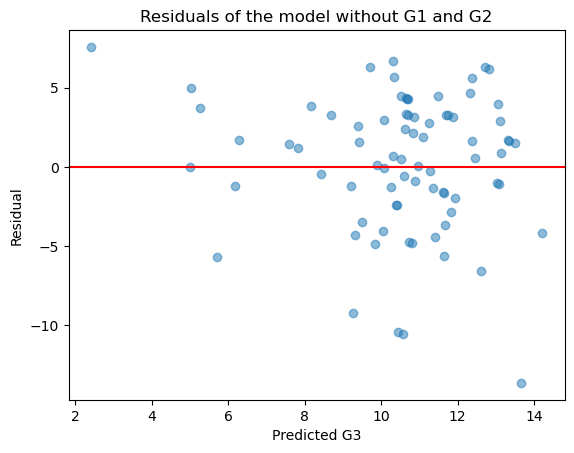

In [27]:
res = y_wo - pred_wo
plt.scatter(pred_wo, res, alpha=0.5)
plt.axhline(0, color='red')
plt.xlabel('Predicted G3')
plt.ylabel('Residual')
plt.title('Residuals of the model without G1 and G2')
plt.show()

In the full dataset, G2 alone has an in-sample R² of about 0.82. A model with G1, G2 and the other variables reaches a test R² of 0.77 (0.93 without zero grades). Without G1 and G2, the test R² drops to about 0.13 (0.18 without zero grades), so lifestyle and family variables explain only a small part of the final grade. The residual plot shows large errors for students with a grade of 0.

In [28]:
cols = base + ['G1', 'G2']

def subgroup_r2(mask, name):
    X = df.loc[mask, cols]
    y_sub = df.loc[mask, 'G3']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y_sub, test_size=0.2, random_state=42
    )

    m = LinearRegression()
    m.fit(X_train, y_train)

    train_r2 = m.score(X_train, y_train)
    test_r2 = m.score(X_test, y_test)
    test_mae = mean_absolute_error(y_test, m.predict(X_test))

    print(
        f'{name:12s} n = {len(y_sub):3d}   '
        f'train R2 = {train_r2:.3f}   '
        f'test R2 = {test_r2:.3f}   '
        f'test MAE = {test_mae:.2f}'
    )

subgroup_r2(df['sex'] == 'M', 'boys')
subgroup_r2(df['sex'] == 'F', 'girls')
subgroup_r2(df['age'] < 17, 'age < 17')
subgroup_r2(df['age'] >= 17, 'age >= 17')


boys         n = 187   train R2 = 0.920   test R2 = 0.768   test MAE = 1.19
girls        n = 208   train R2 = 0.784   test R2 = 0.819   test MAE = 1.43
age < 17     n = 186   train R2 = 0.904   test R2 = 0.896   test MAE = 0.87
age >= 17    n = 209   train R2 = 0.815   test R2 = 0.619   test MAE = 1.49


The model with G1, G2 and the other variables was fitted separately for each subgroup, using an 80% training set and a 20% test set. The final grade prediction results differ between groups. For boys, the test R² is 0.768 and the MAE is 1.19. For girls, the test R² is 0.819 and the MAE is 1.43. These results do not show that the model consistently predicts better for one group. The age-based results also differ: students under 17 have a test R² of 0.896, while students aged 17 or older have a test R² of 0.619. These differences should be interpreted with caution because they are based on a single train-test split.

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

In [30]:
print('Share of students who passed (baseline accuracy):', round(df['passed'].mean(), 3))

y = df['passed']
for c in ['G2', 'failures', 'parents_edu', 'studytime', 'absences']:
    X = df[[c]]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
    acc = model.score(X_test, y_test)
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print(f'{c:12s} accuracy = {acc:.3f}   AUC = {auc:.3f}')

Share of students who passed (baseline accuracy): 0.671
G2           accuracy = 0.873   AUC = 0.958
failures     accuracy = 0.671   AUC = 0.583
parents_edu  accuracy = 0.671   AUC = 0.596
studytime    accuracy = 0.671   AUC = 0.517
absences     accuracy = 0.671   AUC = 0.499


In [31]:
def run_logit(cols, name):
    X = df[cols]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name)
    print('  train accuracy:', round(model.score(X_train, y_train), 3))
    print('  test accuracy: ', round(accuracy_score(y_test, pred), 3))
    print('  test AUC:      ', round(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 3))
    print('  confusion matrix [[TN, FP], [FN, TP]]:')
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=2))
    coefs = pd.Series(model[-1].coef_[0], index=cols).round(2).sort_values()
    return coefs

coefs_wo = run_logit(base, 'Without G1 and G2')
print(coefs_wo, '\n')

coefs_with = run_logit(base + ['G1', 'G2'], 'With G1 and G2')
print(coefs_with)

Without G1 and G2
  train accuracy: 0.744
  test accuracy:  0.671
  test AUC:       0.61
  confusion matrix [[TN, FP], [FN, TP]]:
[[ 7 19]
 [ 7 46]]
              precision    recall  f1-score   support

           0       0.50      0.27      0.35        26
           1       0.71      0.87      0.78        53

    accuracy                           0.67        79
   macro avg       0.60      0.57      0.56        79
weighted avg       0.64      0.67      0.64        79

failures       -0.81
goout          -0.38
absences       -0.18
health         -0.16
internet_num   -0.15
age            -0.08
freetime       -0.05
romantic_num   -0.03
studytime       0.05
parents_edu     0.07
famrel          0.10
sex_num         0.21
higher_num      0.22
alcohol         0.27
dtype: float64 

With G1 and G2
  train accuracy: 0.937
  test accuracy:  0.911
  test AUC:       0.969
  confusion matrix [[TN, FP], [FN, TP]]:
[[24  2]
 [ 5 48]]
              precision    recall  f1-score   support

           

Without G1 and G2, the model achieves a test accuracy of 0.671, which is the same as the baseline accuracy. This means that it performs no better than simply predicting the majority class. The AUC of 0.61 also indicates weak classification performance. With G1 and G2, test accuracy increases to 0.91 (AUC = 0.97), mainly because previous grades are strongly related to the final grade. The test set contains only 79 students.

In [32]:
y_sex = df['sex_num']

# predictors without sex itself (otherwise the target would be a predictor)
base_nosex = [c for c in base if c != 'sex_num']

print('Baseline accuracy (most common sex):', round(max(y_sex.mean(), 1 - y_sex.mean()), 3))

def run_sex(cols):
    X = df[cols]
    X_train, X_test, y_train, y_test = train_test_split(X, y_sex, test_size=0.2, random_state=42, stratify=y_sex)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
    acc = model.score(X_test, y_test)
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    return acc, auc, model

# univariate models
for c in ['Walc', 'freetime', 'studytime', 'G3', 'goout', 'absences', 'health']:
    acc, auc, _ = run_sex([c])
    print(f'{c:10s} accuracy = {acc:.3f}   AUC = {auc:.3f}')

Baseline accuracy (most common sex): 0.527
Walc       accuracy = 0.658   AUC = 0.670
freetime   accuracy = 0.633   AUC = 0.625
studytime  accuracy = 0.620   AUC = 0.592
G3         accuracy = 0.582   AUC = 0.618
goout      accuracy = 0.506   AUC = 0.582
absences   accuracy = 0.532   AUC = 0.493
health     accuracy = 0.494   AUC = 0.511


In [33]:
cols_all = base_nosex + ['G1', 'G2', 'G3']
acc, auc, model_sex = run_sex(cols_all)
print(f'All variables: accuracy = {acc:.3f}   AUC = {auc:.3f}')
print(pd.Series(model_sex[-1].coef_[0], index=cols_all).round(2).sort_values())

All variables: accuracy = 0.608   AUC = 0.661
studytime      -0.74
higher_num     -0.44
romantic_num   -0.35
absences       -0.30
goout          -0.24
G2             -0.18
failures       -0.06
internet_num    0.11
age             0.13
G3              0.20
famrel          0.23
parents_edu     0.30
G1              0.30
health          0.39
freetime        0.40
alcohol         0.66
dtype: float64


In [34]:
subsets = {
    'Lifestyle (goout, freetime, Walc, Dalc, health)': ['goout', 'freetime', 'Walc', 'Dalc', 'health'],
    'Study (studytime, failures, absences, grades)': ['studytime', 'failures', 'absences', 'G1', 'G2', 'G3'],
    'No grades': base_nosex,
    'All variables': cols_all,
}
for name, cols_s in subsets.items():
    acc, auc, _ = run_sex(cols_s)
    print(f'{name:50s} accuracy = {acc:.3f}   AUC = {auc:.3f}')

Lifestyle (goout, freetime, Walc, Dalc, health)    accuracy = 0.646   AUC = 0.658
Study (studytime, failures, absences, grades)      accuracy = 0.658   AUC = 0.664
No grades                                          accuracy = 0.608   AUC = 0.628
All variables                                      accuracy = 0.608   AUC = 0.661


**Interpretation:** The results suggest that some lifestyle and study-related variables are associated with sex in this dataset. Among the individual features, weekend alcohol consumption (Walc) shows the strongest classification result (AUC = 0.670), while study time has a weaker result (AUC = 0.592). These findings represent associations in the data and do not prove causation or establish general differences between boys and girls.

## 3. Conclusions

**Sample.** The dataset contains 395 students (53% girls, 47% boys), almost 90%
of them from school GP. About 67% of the students passed the course
(final grade >= 10).

**Grades.** The final grade G3 is skewed to the left, mostly because 38
students have a grade of 0. Boys have a slightly higher mean grade than girls
(about 10.9 vs 10.0, p = 0.04). The difference between the two schools is not
significant (p = 0.34), but school MS is small (46 students).

**Relationships.** G3 is very strongly correlated with the previous grades G2
(r = 0.90) and G1 (r = 0.80). Among the other factors, past failures have the
strongest negative correlation (r = -0.36) and parents' education a weak
positive one (r = 0.21). When students with G3 = 0 are excluded, absences and alcohol use show negative correlations with final grades (approximately -0.21 and -0.19, respectively). These are associations and should not be interpreted as causal effects.

**Linear regression.** In the full dataset, G2 alone has an in-sample R² of about 0.82.
A model with G1, G2 and the other variables reaches a test R² of 0.77 (0.93
without zero grades). Without G1 and G2 the test R² drops to about 0.13 (0.18
without zero grades), so lifestyle and family variables explain only a small
part of the final grade.

**Logistic regression.** Without G1 and G2 the model achieves an accuracy of 0.671, which is the same as the baseline accuracy of predicting that everyone passes, and its AUC of about 0.61 shows weak classification performance. With G1 and G2 the test accuracy rises to 0.91 (AUC 0.97), but this is mostly because the final grade almost repeats the previous grades.

**Limitations.** The data is observational, covers one subject and two schools,
and the test set is small (79 students), so the results show associations, not
causes. The previous grades almost determine the final grade, which makes the
models with G1 and G2 look better than they are as a tool for understanding
what influences success.

**Possible next steps.** Repeat the analysis for the Portuguese-language
dataset (`student-por.csv`), or try a model that predicts the grade only from
information available before the first exam.